In [15]:
import pandas as pd
import numpy as np
import random

# Pour le GNN
import torch
import torch.nn as nn
import torch.optim as optim
from torch_geometric.data import Data
from torch_geometric.nn import SAGEConv
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import  StandardScaler

# Pour faire un "value counts"
from collections import Counter

# Convertir des str en dict même si eval le fait déjà
import ast 
# Retirer les warnings
import warnings
warnings.filterwarnings('ignore')


---

In [16]:
def top_k_categories(k, subset_restaurants):
        all_categories = []
        for cats in subset_restaurants['categories'].dropna():
            if isinstance(cats, str):
                all_categories.extend([c.strip() for c in cats.split(',')])
        return [cat for cat, _ in Counter(all_categories).most_common(k)]

df_users = pd.read_parquet(r'..\user1.parquet')
df_reviews = pd.read_parquet(r'..\review1.parquet')
df_restaurants = pd.read_json(r"..\business1.json")
# def load():
#     users_df = pd.read_parquet('user1.parquet')
#     reviews_df = pd.read_parquet('review1.parquet')
#     restaurants_df = pd.read_json("business1.json")

#     reviews_df = reviews_df.drop(columns=['useful', 'funny', 'cool', 'date', 'text'])
#     restaurants_df = restaurants_df.drop(columns=['name', 'address', 'city', 'state', 'postal_code',
#        'latitude', 'longitude', 'is_open', 'HairSpecializesIn', 'AcceptsInsurance'])
#     users_df = users_df.drop(columns=['compliment_hot', 'compliment_more', 'compliment_profile',
#        'compliment_cute', 'compliment_list', 'compliment_note', 'compliment_plain',
#        'compliment_cool', 'compliment_funny', 'compliment_writer', 'compliment_photos',
#        'friends', 'name', 'fans', 'useful', 'funny', 'cool', 'elite', 'yelping_since'])

#     top_users = users_df.nlargest(10000, 'review_count')['user_id'].values
#     subset_reviews = reviews_df[reviews_df['user_id'].isin(top_users)].copy()
#     top_restaurants = subset_reviews['business_id'].value_counts().head(5000).index.values
#     subset_reviews = subset_reviews[subset_reviews['business_id'].isin(top_restaurants)].copy()

#     subset_users = users_df[users_df['user_id'].isin(subset_reviews['user_id'].unique())].copy()
#     subset_restaurants = restaurants_df[restaurants_df['business_id'].isin(top_restaurants)].copy()
    
#     return subset_users, subset_restaurants, subset_reviews

# df_subset_users, df_subset_restaurants, subset_reviews = load()


def preprocess_data(users_df, restaurants_df, reviews_df):
    reviews_df = reviews_df.drop(columns=['useful', 'funny', 'cool', 'date', 'text'])
    restaurants_df = restaurants_df.drop(columns=['name', 'address', 'city', 'state', 'postal_code',
       'latitude', 'longitude', 'is_open', 'HairSpecializesIn', 'AcceptsInsurance'])
    users_df = users_df.drop(columns=['compliment_hot', 'compliment_more', 'compliment_profile',
       'compliment_cute', 'compliment_list', 'compliment_note', 'compliment_plain',
       'compliment_cool', 'compliment_funny', 'compliment_writer', 'compliment_photos',
       'friends', 'name', 'fans', 'useful', 'funny', 'cool', 'elite', 'yelping_since'])

    top_users = users_df.nlargest(10000, 'review_count')['user_id'].values
    subset_reviews = reviews_df[reviews_df['user_id'].isin(top_users)].copy()
    top_restaurants = subset_reviews['business_id'].value_counts().head(5000).index.values
    subset_reviews = subset_reviews[subset_reviews['business_id'].isin(top_restaurants)].copy()

    subset_users = users_df[users_df['user_id'].isin(subset_reviews['user_id'].unique())].copy()
    subset_restaurants = restaurants_df[restaurants_df['business_id'].isin(top_restaurants)].copy()

    subset_users['review_count_log'] = np.log1p(subset_users['review_count'])
    subset_users['average_stars_norm'] = subset_users['average_stars'] / 5.0
    user_features_cols = ['review_count_log', 'average_stars_norm']

    col_to_dict = ["BusinessParking", "Ambience", "GoodForMeal"]
    for col in col_to_dict:
        subset_restaurants[col] = subset_restaurants[col].apply(lambda x: ast.literal_eval(x))

    subset_restaurants['stars_norm'] = subset_restaurants['stars'] / 5.0
    subset_restaurants['review_count_log'] = np.log1p(subset_restaurants['review_count'])
    subset_restaurants['RestaurantsPriceRange2'] = pd.to_numeric(subset_restaurants['RestaurantsPriceRange2'], errors='coerce').fillna(2.0)
    subset_restaurants['price_norm'] = subset_restaurants['RestaurantsPriceRange2'] / 4.0


    top_k_cat = top_k_categories(50, subset_restaurants)
    rmv_list = ['Food', 'Event Planning & Services', 'Venues & Event Spaces', 'Restaurants']
    top_k_cat = [i for i in top_k_cat if i not in rmv_list]

    for cat in top_k_cat:
        subset_restaurants[f'cat_{cat}'] = subset_restaurants['categories'].apply(
            lambda x: 1.0 if isinstance(x, str) and cat in x else 0.0
        )

    boolean_attrs = [
        'RestaurantsDelivery', 'OutdoorSeating', 'BusinessAcceptsCreditCards',
        'BikeParking', 'RestaurantsTakeOut', 'GoodForKids', 'Caters',
        'RestaurantsReservations', 'RestaurantsTableService', 'RestaurantsGoodForGroups',
        'WheelchairAccessible', 'HasTV', 'HappyHour', 'DriveThru',
        'BusinessAcceptsBitcoin', 'DogsAllowed', 'Open24Hours'
    ]

    def parse_boolean(val):
        if pd.isna(val) or val is None or val == 'None':
            return 0.0
        if isinstance(val, bool):
            return 1.0 if val else 0.0
        if isinstance(val, str):
            val = val.lower()
            if val in ['true', '1', 'yes']:
                return 1.0
            if val in ['false', '0', 'no']:
                return 0.0
        return 0.0

    for attr in boolean_attrs:
        if attr in subset_restaurants.columns:
            subset_restaurants[f'{attr}_bool'] = subset_restaurants[attr].apply(parse_boolean)

    categorical_attrs = {
        'WiFi': ['free', 'no', 'paid'],
        'Alcohol': ['full_bar', 'beer_and_wine', 'none'],
        'NoiseLevel': ['quiet', 'average', 'loud', 'very_loud'],
        'RestaurantsAttire': ['casual', 'dressy', 'formal'],
        'Smoking': ['no', 'yes', 'outdoor'],
        'BusinessParking': ['garage', 'lot', 'street', 'valet', 'validated'],
        'Ambience': ['casual', 'classy', 'divey', 'hipster', 'intimate', 'romantic', 'touristy', 'trendy','upscale'],
        'GoodForMeal': ['lunch', 'brunch', 'dessert', 'dinner', 'latenight', 'breakfast']
    }

    for attr, values in categorical_attrs.items():
        if attr in subset_restaurants.columns:
            for val in values:
                subset_restaurants[f'{attr}_{val}'] = subset_restaurants[attr].apply(
                    lambda x: 1.0 if isinstance(x, str) and val in x.lower() and x != "None" else 0.0
                )

    restaurant_features_cols = (
        ['stars_norm', 'review_count_log', 'price_norm']
        + [f'cat_{cat}' for cat in top_k_cat]
        + [f'{attr}_bool' for attr in boolean_attrs if attr in subset_restaurants.columns]
        + [f'{attr}_{val}' for attr, values in categorical_attrs.items()
           for val in values if attr in subset_restaurants.columns]
    )

    subset_restaurants_fillna = subset_restaurants[restaurant_features_cols].fillna(0)
    subset_users_fillna = subset_users[user_features_cols].fillna(0)

    return subset_users, subset_restaurants, subset_reviews, subset_users_fillna, subset_restaurants_fillna

subset_users, subset_restaurants, subset_reviews, subset_users_fillna, subset_restaurants_fillna = preprocess_data(df_users, df_restaurants, df_reviews)

---

In [4]:
# def get_propositions(idx):

#     for i in idx:
#         if len(i) != 0:
#             print(subset_restaurants[subset_restaurants.index.isin(i) & (subset_restaurants["stars"]>=3)].sort_values(by = "stars", ascending=False).sample(5 if len(i)>=5 else len(i)))


# def select_categories(user_id):
#     print("What type of food do you prefer ?")
#     cat = top_k_categories(30, subset_restaurants)
#     print(cat)
#     # provisoire car on n'a pas d'interface encore 
#     # Pas de blindage ici
#     ipt = str(input("Input: ")).split()
#     idx = []
#     for i in ipt:
#         idx.append(subset_restaurants[subset_restaurants["categories"].str.contains(i)].index.tolist())
    
#     get_propositions(idx)

#     print("\n# Like/ Dislike:")
#     ipt_rest = str(input("Restaurant ID's:")).split()
#     ipt_labels = list(map(int, str(input("Lables:")).split()))
#     return add_edge(user_id, ipt_rest, ipt_labels)


    


In [5]:
# def generate_user_id():
#     user_id = "".join([chr(random.randint(48, 125)) for _ in range(22)])
#     if user_id in user_to_idx:
#         generate_user_id()
#     else:
#         return user_id
    

# def add_user():
#     new_user_features_raw = np.array([[0, 0.7]])

#     # Normalisation
#     new_user_features = scaler_user.transform(new_user_features_raw)

#     new_user_features_padded = np.pad(
#         new_user_features,
#         ((0, 0), (0, max_dim - new_user_features.shape[1])),
#         mode='constant'
#     )

#     user_id = generate_user_id()
#     user_to_idx[user_id] = len(restaurant_to_idx)+len(user_to_idx)

#     graph_data.x = torch.cat([
#             graph_data.x,
#             torch.FloatTensor(new_user_features_padded)
#         ], dim=0)
    
#     return user_id



In [6]:
# def cold_start():
#     u_id = add_user()
#     val = select_categories(u_id)
#     if val:
#         print("Success !")
#     else:
#         print("Error...")
    
#     return u_id 

# id = cold_start()

# recs = get_top_k_recommendations(id, k=10)
    

---


In [7]:
import torch
from torch_geometric.data import Data
from sklearn.preprocessing import StandardScaler
import numpy as np

user_to_idx_lp = dict()
restaurant_to_idx_lp = dict()
restaurant_idx_id_lp = dict()
max_dim = None
scaler_user = StandardScaler()
scaler_restaurant = StandardScaler()
user_features = scaler_user.fit_transform(subset_users_fillna)
restaurant_features = scaler_restaurant.fit_transform(subset_restaurants_fillna)

def build_graph_link_predictor(subset_users, subset_restaurants, subset_reviews):

    global user_to_idx_lp, restaurant_to_idx_lp, restaurant_idx_id_lp, max_dim
    
    user_to_idx_lp = {uid: i for i, uid in enumerate(subset_users['user_id'])}

    num_users = len(user_to_idx_lp)

    restaurant_to_idx_lp = {rid: i + num_users for i, rid in enumerate(subset_restaurants['business_id'])}
    restaurant_idx_id_lp = {i + num_users: rid for i, rid in enumerate(subset_restaurants['business_id'])}


    max_dim = max(user_features.shape[1], restaurant_features.shape[1])

    user_features_padded = np.pad(
        user_features,
        ((0, 0), (0, max_dim - user_features.shape[1])),
        mode='constant'
    )

    restaurant_features_padded = np.pad(
        restaurant_features,
        ((0, 0), (0, max_dim - restaurant_features.shape[1])),
        mode='constant'
    )

    all_features = np.vstack([user_features_padded, restaurant_features_padded])
    x = torch.FloatTensor(all_features)

    edge_list = []

    interactions = subset_reviews[
        subset_reviews['user_id'].isin(user_to_idx_lp)
        & subset_reviews['business_id'].isin(restaurant_to_idx_lp)
    ]

    for _, row in interactions.iterrows():
        u = user_to_idx_lp[row['user_id']]
        r = restaurant_to_idx_lp[row['business_id']]
        edge_list.append([u, r])
        edge_list.append([r, u])

    edge_index = torch.LongTensor(edge_list).t().contiguous()
    graph = Data(x=x, edge_index=edge_index)

    print(f"Number of nodes: {graph.num_nodes}")
    print(f"Number of edges: {graph.num_edges}")

    return graph


graph_data = build_graph_link_predictor(
    subset_users,
    subset_restaurants,
    subset_reviews
)


Number of nodes: 14892
Number of edges: 337124


In [20]:
user_to_idx_lp["qVc8ODYU5SZjKXVBgXdI7w"]

0

In [8]:
# E2: GNN 1: LinkPredictor

import torch
import torch.nn as nn
from torch_geometric.nn import SAGEConv
from torch_geometric.transforms import RandomLinkSplit
from torch_geometric.data import Data


class GNNLinkPredictor(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()
        self.in_channels = in_channels
        self.hidden_channels = hidden_channels
        self.out_channels = out_channels
        self.conv1 = SAGEConv(in_channels, hidden_channels)
        self.conv2 = SAGEConv(hidden_channels, out_channels)
        self.relu = nn.ReLU()

    def encode(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = self.relu(x)
        x = self.conv2(x, edge_index)
        return x

    def decode(self, z, edge_label_index):
        # Produit scalaire entre embeddings source et destination
        src = z[edge_label_index[0]]
        dst = z[edge_label_index[1]]
        return (src * dst).sum(dim=1)

    def forward(self, x, edge_index, edge_label_index):
        z = self.encode(x, edge_index)
        return self.decode(z, edge_label_index)
    
    def save(self, filepath):
        torch.save({
            "state_dict": self.state_dict(),
            "in_channels": self.in_channels,
            "hidden_channels": self.hidden_channels,
            "out_channels": self.out_channels
        }, filepath)

    @classmethod
    def load(cls, filepath, device="cpu"):
        checkpoint = torch.load(filepath, map_location=device)

        model = cls(
            checkpoint["in_channels"],
            checkpoint["hidden_channels"],
            checkpoint["out_channels"]
        )
        model.load_state_dict(checkpoint["state_dict"])
        model.to(device)
        model.eval()

        return model

transform = RandomLinkSplit(
    num_val=0.1,
    num_test=0.1,
    is_undirected=True,
    add_negative_train_samples=True  # Génère des arêtes négatives pour l'entraînement
)

train_data, val_data, test_data = transform(graph_data)


Epoch 000 | Train Loss: 0.8578 | Val Loss: 0.8079 | AUC Train: 0.2957 | AUC Val: 0.3294
Epoch 005 | Train Loss: 0.7025 | Val Loss: 0.6960 | AUC Train: 0.5694 | AUC Val: 0.5974
Epoch 010 | Train Loss: 0.6655 | Val Loss: 0.6681 | AUC Train: 0.7349 | AUC Val: 0.7082
Epoch 015 | Train Loss: 0.6308 | Val Loss: 0.6378 | AUC Train: 0.7665 | AUC Val: 0.7394
Epoch 020 | Train Loss: 0.6080 | Val Loss: 0.6230 | AUC Train: 0.7872 | AUC Val: 0.7597
Epoch 025 | Train Loss: 0.5899 | Val Loss: 0.6071 | AUC Train: 0.8199 | AUC Val: 0.7881
Epoch 030 | Train Loss: 0.5740 | Val Loss: 0.5960 | AUC Train: 0.8437 | AUC Val: 0.8051
Epoch 035 | Train Loss: 0.5580 | Val Loss: 0.5848 | AUC Train: 0.8636 | AUC Val: 0.8201


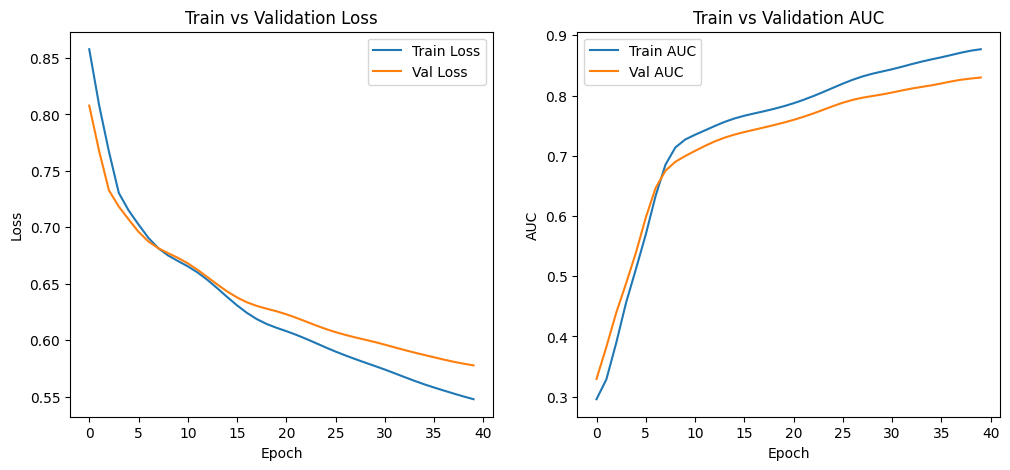

In [9]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

model_linkpred = GNNLinkPredictor(
    in_channels=graph_data.num_node_features,
    hidden_channels=128,
    out_channels=64
).to(device)

optimizer = torch.optim.Adam(model_linkpred.parameters(), lr=0.005, weight_decay=5e-3)
criterion = nn.BCEWithLogitsLoss()


num_epochs = 40

# Stockage des metrics
train_losses, val_losses = [], []
train_aucs, val_aucs = [], []

for epoch in range(num_epochs):
    model_linkpred.train()
    optimizer.zero_grad()

    edge_label_index = train_data.edge_label_index.to(device)
    edge_label = train_data.edge_label.to(device)

    out = model_linkpred(train_data.x.to(device), train_data.edge_index.to(device), edge_label_index)
    loss = criterion(out, edge_label)
    loss.backward()
    optimizer.step()

    # Stocker metrics train
    train_losses.append(loss.item())
    pred_prob = torch.sigmoid(out).cpu().detach().numpy()
    train_aucs.append(roc_auc_score(edge_label.cpu(), pred_prob))

    # Validation
    model_linkpred.eval()
    with torch.no_grad():
        val_edge_index = val_data.edge_label_index.to(device)
        val_edge_label = val_data.edge_label.to(device)

        val_out = model_linkpred(val_data.x.to(device), val_data.edge_index.to(device), val_edge_index)
        val_loss = criterion(val_out, val_edge_label)
        val_losses.append(val_loss.item())

        val_pred_prob = torch.sigmoid(val_out).cpu().numpy()
        val_aucs.append(roc_auc_score(val_edge_label.cpu(), val_pred_prob))

    if epoch % 5 == 0:
        print(f"Epoch {epoch:03d} | Train Loss: {loss:.4f} | Val Loss: {val_loss:.4f} | "
              f"AUC Train: {train_aucs[-1]:.4f} | AUC Val: {val_aucs[-1]:.4f}")



import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train vs Validation Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(train_aucs, label='Train AUC')
plt.plot(val_aucs, label='Val AUC')
plt.xlabel("Epoch")
plt.ylabel("AUC")
plt.title("Train vs Validation AUC")
plt.legend()

plt.show()


In [10]:
user_to_idx_ep = dict()
restaurant_to_idx_ep = dict()
restaurant_idx_id_ep = dict()


def build_graph_gnn_edge_predictor(subset_users, subset_restaurants, subset_reviews):

    global user_to_idx_ep, restaurant_to_idx_ep, restaurant_idx_id_ep, user_features, restaurant_features
    user_to_idx_ep = {uid: i for i, uid in enumerate(subset_users['user_id'])}
    num_users = len(user_to_idx_ep)

    restaurant_to_idx_ep = {rid: i + num_users for i, rid in enumerate(subset_restaurants['business_id'])}
    restaurant_idx_id_ep = {i + num_users: rid for i, rid in enumerate(subset_restaurants['business_id'])}

    max_dim = max(user_features.shape[1], restaurant_features.shape[1])

    user_features_padded = np.pad(
        user_features,
        ((0, 0), (0, max_dim - user_features.shape[1])),
        mode='constant'
    )

    restaurant_features_padded = np.pad(
        restaurant_features,
        ((0, 0), (0, max_dim - restaurant_features.shape[1])),
        mode='constant'
    )

    all_features = np.vstack([user_features_padded, restaurant_features_padded])
    x = torch.FloatTensor(all_features)

    edge_list = []
    edge_labels = []

    likes = subset_reviews[subset_reviews['stars'] >= 3]
    for _, row in likes.iterrows():
        if row['user_id'] in user_to_idx_ep and row['business_id'] in restaurant_to_idx_ep:
            u = user_to_idx_ep[row['user_id']]
            r = restaurant_to_idx_ep[row['business_id']]
            edge_list.append([u, r])
            edge_list.append([r, u])
            edge_labels.extend([1.0, 1.0])

    dislikes = subset_reviews[subset_reviews['stars'] <= 2]
    for _, row in dislikes.iterrows():
        if row['user_id'] in user_to_idx_ep and row['business_id'] in restaurant_to_idx_ep:
            u = user_to_idx_ep[row['user_id']]
            r = restaurant_to_idx_ep[row['business_id']]
            edge_list.append([u, r])
            edge_list.append([r, u])
            edge_labels.extend([0.0, 0.0])

    edge_index = torch.LongTensor(edge_list).t().contiguous()
    edge_label = torch.FloatTensor(edge_labels)

    graph = Data(x=x, edge_index=edge_index, edge_label=edge_label)

    print(f"Edges: {edge_index.shape[1]:,}")
    print(f"Likes: {(edge_label == 1.0).sum().item():,}")
    print(f"Dislikes: {(edge_label == 0.0).sum().item():,}")

    return graph


graph_with_labels = build_graph_gnn_edge_predictor(subset_users, subset_restaurants, subset_reviews)


Edges: 337,124
Likes: 310,604
Dislikes: 26,520


In [11]:
import torch
from torch_geometric.data import Data
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from torch_geometric.nn import SAGEConv

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
class GNNEdgeLabelPredictor(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super().__init__()
        self.in_channels = in_channels
        self.hidden_channels = hidden_channels
        self.out_channels = out_channels
        
        self.conv1 = SAGEConv(in_channels, hidden_channels)
        self.conv2 = SAGEConv(hidden_channels, out_channels)
        self.relu = nn.ReLU()
        self.predictor = nn.Sequential(
            nn.Linear(out_channels*2, hidden_channels),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(hidden_channels, 1)
        )

    def encode(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = self.relu(x)
        x = self.conv2(x, edge_index)
        return x

    def decode(self, z, edge_label_index):
        src = z[edge_label_index[0]]
        dst = z[edge_label_index[1]]
        return self.predictor(torch.cat([src, dst], dim=1)).squeeze()

    def forward(self, x, edge_index, edge_label_index):
        z = self.encode(x, edge_index)
        return self.decode(z, edge_label_index)
    
    def save(self, filepath):
        torch.save({
            "state_dict": self.state_dict(),
            "in_channels": self.in_channels,
            "hidden_channels": self.hidden_channels,
            "out_channels": self.out_channels
        }, filepath)

    def load_weights(self, filepath, device="cpu"):
        """
        Charge les poids du checkpoint dans l'instance existante.
        """
        checkpoint = torch.load(filepath, map_location=device)
        self.load_state_dict(checkpoint["state_dict"])
        self.to(device)
        self.eval()

    @classmethod
    def load(cls, filepath, device="cpu"):
        checkpoint = torch.load(filepath, map_location=device)

        model = cls(
            checkpoint["in_channels"],
            checkpoint["hidden_channels"],
            checkpoint["out_channels"]
        )
        model.load_state_dict(checkpoint["state_dict"])
        model.to(device)
        model.eval()

        return model
    

In [12]:
def create_bidirectional(edges, labels):
    bi_edges, bi_labels = [], []
    for edge, label in zip(edges, labels):
        bi_edges.append(edge)
        bi_labels.append(label)
        bi_edges.append([edge[1], edge[0]])
        bi_labels.append(label)
    return bi_edges, bi_labels


def prepare_edge_splits(graph_with_labels, test_size=0.2, val_size=0.1, random_state=42):
    import torch
    from sklearn.model_selection import train_test_split

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

    edges = graph_with_labels.edge_index.t().tolist()
    labels = graph_with_labels.edge_label.tolist()

    unique_edges = []
    unique_labels = []
    seen = set()

    for edge, label in zip(edges, labels):
        u, v = edge
        edge_norm = tuple(sorted([u, v]))
        if edge_norm not in seen:
            unique_edges.append([u, v])
            unique_labels.append(label)
            seen.add(edge_norm)

    print(f"Edges originaux: {len(edges)}")
    print(f"Edges uniques (après dédoublonnage): {len(unique_edges)}")

    train_edges, test_edges, train_labels, test_labels = train_split = train_test_split(
        unique_edges,
        unique_labels,
        test_size=test_size,
        random_state=random_state,
        stratify=unique_labels
    )

    train_edges, val_edges, train_labels, val_labels = train_test_split(
        train_edges,
        train_labels,
        test_size=val_size,
        random_state=random_state,
        stratify=train_labels
    )

    print(f"\nTrain: {len(train_edges)} edges")
    print(f"Val:   {len(val_edges)} edges")
    print(f"Test:  {len(test_edges)} edges")

    train_edges_bi, train_labels_bi = create_bidirectional(train_edges, train_labels)
    val_edges_bi, val_labels_bi = create_bidirectional(val_edges, val_labels)
    test_edges_bi, test_labels_bi = create_bidirectional(test_edges, test_labels)

    train_edge_index = torch.tensor(train_edges_bi, dtype=torch.long).t().to(device)
    train_edge_label = torch.tensor(train_labels_bi, dtype=torch.long).to(device)

    val_edge_index = torch.tensor(val_edges_bi, dtype=torch.long).t().to(device)
    val_edge_label = torch.tensor(val_labels_bi, dtype=torch.long).to(device)

    test_edge_index = torch.tensor(test_edges_bi, dtype=torch.long).t().to(device)
    test_edge_label = torch.tensor(test_labels_bi, dtype=torch.long).to(device)

    print(f"\nAprès bidirectionnalisation :")
    print(f"Train: {train_edge_index.shape[1]} edges")
    print(f"Val:   {val_edge_index.shape[1]} edges")
    print(f"Test:  {test_edge_index.shape[1]} edges")

    return (
        train_edge_index, train_edge_label,
        val_edge_index, val_edge_label,
        test_edge_index, test_edge_label
    )

train_edge_index, train_edge_label, val_edge_index, val_edge_label, test_edge_index, test_edge_label = prepare_edge_splits(graph_with_labels)

Edges originaux: 337124
Edges uniques (après dédoublonnage): 156521

Train: 112694 edges
Val:   12522 edges
Test:  31305 edges

Après bidirectionnalisation :
Train: 225388 edges
Val:   25044 edges
Test:  62610 edges


pos_weight = 0.07834956844583087
Edges in train: 225388
Edges in val: 25044
Overlap: 0
Epoch 000 | Train Loss: 0.1007 | Val Loss: 0.1005 | AUC Train: 0.5182 | AUC Val: 0.5662 | Train Acc: 0.7129 | Val Acc: 0.7021
Epoch 001 | Train Loss: 0.1005 | Val Loss: 0.1003 | AUC Train: 0.5456 | AUC Val: 0.6011 | Train Acc: 0.6236 | Val Acc: 0.6141
Epoch 002 | Train Loss: 0.1003 | Val Loss: 0.1001 | AUC Train: 0.5747 | AUC Val: 0.6238 | Train Acc: 0.5726 | Val Acc: 0.5815
Epoch 003 | Train Loss: 0.1001 | Val Loss: 0.0999 | AUC Train: 0.5959 | AUC Val: 0.6380 | Train Acc: 0.5549 | Val Acc: 0.5881
Epoch 004 | Train Loss: 0.0998 | Val Loss: 0.0997 | AUC Train: 0.6149 | AUC Val: 0.6470 | Train Acc: 0.5637 | Val Acc: 0.6106
Epoch 005 | Train Loss: 0.0996 | Val Loss: 0.0995 | AUC Train: 0.6271 | AUC Val: 0.6530 | Train Acc: 0.5826 | Val Acc: 0.6339
Epoch 006 | Train Loss: 0.0994 | Val Loss: 0.0993 | AUC Train: 0.6419 | AUC Val: 0.6572 | Train Acc: 0.6076 | Val Acc: 0.6516
Epoch 007 | Train Loss: 0.0992 

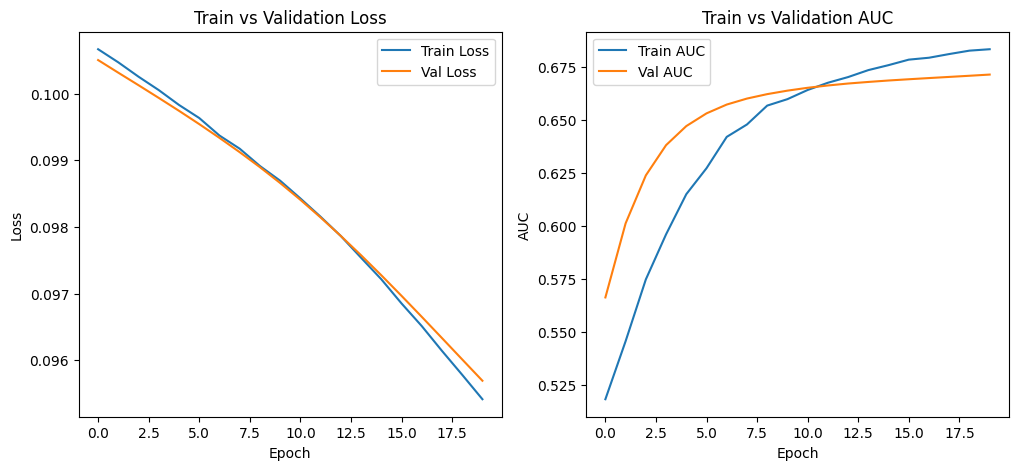

In [13]:
train_losses, val_losses = [], []
train_aucs, val_aucs = [], []
train_accs, val_accs = [], []

pos = train_edge_label.sum().item()
neg = len(train_edge_label) - pos
pos_weight = neg / pos
print("pos_weight =", pos_weight)

model_labelpred = GNNEdgeLabelPredictor(
    in_channels=graph_with_labels.x.size(1),
    hidden_channels=512,
    out_channels=256
).to(device)

criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight], device=device))
optimizer = torch.optim.Adam(model_labelpred.parameters(), lr=0.0001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', factor=0.0001, patience=5
)

num_epochs = 20

x = graph_with_labels.x.to(device)
# Vérifier qu'il n'y a pas de fuite
train_edges_set = set(map(tuple, train_edge_index.t().tolist()))
val_edges_set = set(map(tuple, val_edge_index.t().tolist()))
overlap = train_edges_set & val_edges_set

print(f"Edges in train: {len(train_edges_set)}")
print(f"Edges in val: {len(val_edges_set)}")
print(f"Overlap: {len(overlap)}") 

if len(overlap) > 0:
    print("ATTENTION: Fuite de données train/val !")
for epoch in range(num_epochs):
    model_labelpred.train()
    optimizer.zero_grad()
    out = model_labelpred(x, graph_with_labels.edge_index.to(device), train_edge_index.to(device))
    loss = criterion(out, train_edge_label.float().to(device))
    loss.backward()
    optimizer.step()

    # Stocker train metrics
    train_losses.append(loss.item())
    train_probs = torch.sigmoid(out).cpu().detach().numpy() 
    train_true = train_edge_label.cpu().numpy()
    train_aucs.append(roc_auc_score(train_true, train_probs))
    train_accs.append(((train_probs > 0.5) == train_true).mean())

    # Validation
    model_labelpred.eval()
    with torch.no_grad():
        val_out = model_labelpred(x, graph_with_labels.edge_index.to(device), val_edge_index.to(device))
        val_loss = criterion(val_out, val_edge_label.float().to(device))
        val_losses.append(val_loss.item())

        val_probs = torch.sigmoid(val_out).cpu().numpy()
        val_true = val_edge_label.cpu().numpy()
        val_aucs.append(roc_auc_score(val_true, val_probs))
        val_accs.append(((val_probs > 0.5) == val_true).mean())

    
        print(f"Epoch {epoch:03d} | Train Loss: {loss:.4f} | Val Loss: {val_loss:.4f} | "
              f"AUC Train: {train_aucs[-1]:.4f} | AUC Val: {val_aucs[-1]:.4f} | "
              f"Train Acc: {train_accs[-1]:.4f} | Val Acc: {val_accs[-1]:.4f}")
        scheduler.step(val_aucs[-1]) 

    

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Train vs Validation Loss")
plt.legend()

plt.subplot(1,2,2)
plt.plot(train_aucs, label='Train AUC')
plt.plot(val_aucs, label='Val AUC')
plt.xlabel("Epoch")
plt.ylabel("AUC")
plt.title("Train vs Validation AUC")
plt.legend()

plt.show()


In [14]:
model_labelpred = GNNEdgeLabelPredictor(
    in_channels=graph_with_labels.x.size(1),
    hidden_channels=512,
    out_channels=256
).to(device)
model_labelpred = model_labelpred.load("label_pred.pth")


model_linkpred = GNNLinkPredictor(
    in_channels=graph_data.num_node_features,
    hidden_channels=128,
    out_channels=64
).to(device)
model_linkpred = model_linkpred.load("link_pred.pth")


def get_top_k_rec(user_id, top_k, model_linkpred, model_labelpred):



    user_idx = user_to_idx_lp[user_id]
    model_linkpred.eval()
    with torch.no_grad():
        z_link = model_linkpred.encode(graph_data.x.to(device), graph_data.edge_index.to(device))
        
        # Tous les restaurants possibles pour cet utilisateur
        restaurant_indices = torch.tensor(list(restaurant_to_idx_lp.values()), device=device)
        user_indices = torch.full_like(restaurant_indices, user_idx, device=device)
        edge_candidates = torch.stack([user_indices, restaurant_indices], dim=0)
        
        # Score de relation
        scores = model_linkpred.decode(z_link, edge_candidates)
        probs_link = torch.sigmoid(scores)
        
        # Filtrer les arêtes les plus probables
        threshold = 0.5
        selected_edges = edge_candidates[:, probs_link > threshold]

    model_labelpred.eval()
    with torch.no_grad():
        z_label = model_labelpred.encode(graph_with_labels.x.to(device), graph_with_labels.edge_index.to(device))
        like_scores = model_labelpred.decode(z_label, selected_edges)
        like_probs = torch.sigmoid(like_scores)


    top_indices = torch.topk(like_probs, k=top_k).indices
    recommended_restaurants_idx = selected_edges[1, top_indices].cpu().numpy()
    recommended_restaurants = [restaurant_idx_id_ep[i] for i in recommended_restaurants_idx]


    return recommended_restaurants

FileNotFoundError: [Errno 2] No such file or directory: 'label_pred.pth'

In [ ]:
user_id = a
recommended_restaurants = get_top_k_rec(user_id, 10, model_linkpred, model_labelpred)
print(f"Top recommendation for user {user_id}:")
for row in subset_restaurants[subset_restaurants["business_id"].isin(recommended_restaurants)].iterrows():
    print(f"Restaurant ID: {row[1]['business_id']} | Stars: {row[1]['stars']} | Categories: {row[1]['categories']}")

In [ ]:
import torch
import numpy as np
import random

def generate_user_id():
    user_id = "".join([chr(random.randint(48, 125)) for _ in range(22)])
    if user_id in user_to_idx_lp:
        return generate_user_id()
    return user_id

def create_user() -> str:
    user_id = generate_user_id()
    new_idx = max(
        max(user_to_idx_lp.values(), default=-1),
        max(restaurant_to_idx_lp.values(), default=-1),
        max(user_to_idx_ep.values(), default=-1),
        max(restaurant_to_idx_ep.values(), default=-1)
    ) + 1

    # Valeurs par défaut avant padding : [review_count, avg_stars_scaled]
    default_raw = np.array([[0.0, 0.7]])
    default_scaled = scaler_user.transform(default_raw)

    # Padding pour atteindre max_dim
    default_padded = np.pad(
        default_scaled,
        ((0, 0), (0, max_dim - default_scaled.shape[1])),
        mode='constant'
    )

    default_feat = torch.tensor(default_padded, dtype=torch.float32).squeeze(0)

    # Ajouter le user au graphe LinkPredictor
    user_to_idx_lp[user_id] = new_idx
    graph_data.x = torch.cat([graph_data.x, default_feat.unsqueeze(0)], dim=0)

    # Ajouter le user au graphe EdgeLabelPredictor
    user_to_idx_ep[user_id] = new_idx
    graph_with_labels.x = torch.cat([graph_with_labels.x, default_feat.unsqueeze(0)], dim=0)

    return user_id

def add_user_relations(user_id: str, rest_id_list: list[str], preference_list: list[int]) -> bool:
    if len(rest_id_list) != len(preference_list):
        return False

    # Vérifier que tous les restaurants existent
    for r in rest_id_list:
        if r not in restaurant_to_idx_ep:
            return False

    # User index dans EdgeLabelPredictor
    if user_id not in user_to_idx_ep:
        new_user_idx_ep = max(max(user_to_idx_ep.values()), max(restaurant_to_idx_ep.values())) + 1
        user_to_idx_ep[user_id] = new_user_idx_ep
        user_vec = torch.zeros(max_dim)
        graph_with_labels.x = torch.cat([graph_with_labels.x, user_vec.unsqueeze(0)], dim=0)

    def _update_graph(graph, user_idx, rest_to_idx):
        edge_list = graph.edge_index.T.tolist()
        labels = graph.edge_label.cpu().tolist() if hasattr(graph, "edge_label") else [0] * len(edge_list)

        # Liste des arêtes existantes pour ce user
        exist_edges = {r: lbl for (u, r), lbl in zip(edge_list, labels) if u == user_idx}

        rmv = []
        # Mettre à jour les labels existants si nécessaire
        for i, (res, pref) in enumerate(zip(rest_id_list, preference_list)):
            ridx = rest_to_idx[res]
            if ridx in exist_edges:
                if pref == exist_edges[ridx]:
                    rmv.append(i)  # rien à faire, label identique
                else:
                    # Trouver l'indice exact de l'arête à mettre à jour
                    mask = (graph.edge_index[0] == user_idx) & (graph.edge_index[1] == ridx)
                    idx = mask.nonzero(as_tuple=True)[0].item()
                    graph.edge_label[idx] = float(pref)
                    # Arête inverse
                    mask_inv = (graph.edge_index[0] == ridx) & (graph.edge_index[1] == user_idx)
                    idx_inv = mask_inv.nonzero(as_tuple=True)[0].item()
                    graph.edge_label[idx_inv] = float(pref)
                    rmv.append(i)

        # Supprimer les relations déjà traitées
        new_rest = [rest_id_list[i] for i in range(len(rest_id_list)) if i not in rmv]
        new_pref = [preference_list[i] for i in range(len(preference_list)) if i not in rmv]

        # Ajouter les nouvelles arêtes
        new_edges = []
        new_labels = []
        for res, pref in zip(new_rest, new_pref):
            ridx = rest_to_idx[res]
            new_edges.extend([[user_idx, ridx], [ridx, user_idx]])
            new_labels.extend([float(pref), float(pref)])

        if new_edges:
            new_edge_index = torch.tensor(new_edges, dtype=torch.long).t().contiguous()
            new_edge_label = torch.tensor(new_labels, dtype=torch.float)
            graph.edge_index = torch.cat([graph.edge_index, new_edge_index], dim=1)
            if hasattr(graph, "edge_label"):
                graph.edge_label = torch.cat([graph.edge_label, new_edge_label])
            else:
                graph.edge_label = new_edge_label

    # Mettre à jour uniquement le graphe EdgeLabelPredictor
    _update_graph(graph_with_labels, user_to_idx_ep[user_id], restaurant_to_idx_ep)

    return True


In [ ]:
a = create_user()


In [ ]:
max_idx = graph_data.edge_index.max().item()
print("Max edge_index:", max_idx)
print("Number of nodes:", graph_data.x.shape[0])


In [ ]:
add_user_relations(a, ['MTSW4McQd7CbVtyjqoe9mw', 'IDtLPgUrqorrpqSLdfMhZQ', "X_E7U2lVNEwbH_gpOBmAHQ"], [1, 1, 1])

In [ ]:
user_to_idx_lp[a]

In [ ]:
edge = graph_with_labels.edge_index.T.cpu().tolist()
edges = []
for elt in edge:
    if elt[0] == 14893:
        edges.append(elt)
print(edges)

In [ ]:
def cold_start():
    # 1. Création du user dans les deux graphes
    user_id = create_user()

    # 2. Demande des catégories préférées à l'utilisateur
    print("What type of food do you prefer?")
    cat = top_k_categories(30, subset_restaurants)
    print(cat)

    # Pour l'instant, l'interface est manuelle
    ipt = str(input("Input categories (separated by space): ")).split()
    idx = []
    for i in ipt:
        idx.append(subset_restaurants[subset_restaurants["categories"].str.contains(i)].index.tolist())

    # Afficher des propositions basées sur les catégories choisies
    for i in idx:
        if len(i) != 0:
            sample_count = 5 if len(i) >= 5 else len(i)
            print(subset_restaurants[subset_restaurants.index.isin(i) & (subset_restaurants["stars"] >= 3)]
                  .sort_values(by="stars", ascending=False)
                  .sample(sample_count))

    # 3. L'utilisateur choisit les restaurants et les labels
    print("\n# Like / Dislike:")
    ipt_rest = str(input("Restaurant IDs: ")).split()
    ipt_labels = list(map(int, str(input("Labels (0/1): ")).split()))

    # 4. Ajouter les relations dans les deux graphes
    val = add_user_relations(user_id, ipt_rest, ipt_labels)

    if val:
        print("Success!")
    else:
        print("Error...")

    return user_id


In [ ]:
a = cold_start()

In [ ]:
rest = ["TjwWB-ET-qmO2-8bfIHMig", "EO5ne2jClfd16Sus5D6i6A", "2Q1R2OhBbAQ581vK_r7NhA", "aJzuFdUnxwhESwAnsegR4g", "Cckfq1IRAAN4Q7YJh7Ru6A"]

In [ ]:
subset_restaurants[subset_restaurants["business_id"].isin(rest)]